# RNN、GRU 与 LSTM

本 Notebook 包含网络结构，以及基于 Tatoeba 语料的中文下一词预测示例，可比较三种模型的训练曲线、测试指标和续写效果。
为便于理解递推过程，使用 `nn.Linear` 手写单步计算，再沿时间维展开；不直接调用 `nn.RNN`、`nn.GRU` 或 `nn.LSTM`。

统一采用单层、单向结构，输入为 `(batch_size, seq_len, input_dim)`。
每个时间步通过线性输出层产生未归一化输出，返回 `outputs, final_state`。
`outputs` 形状为 `(batch_size, seq_len, output_dim)`；普通隐藏状态为 `(batch_size, hidden_dim)`，
LSTM 状态为 `(h, c)`。省略初始状态时，以与输入同设备、同精度的零张量初始化。
序列必须非空，暂不支持 padding mask、变长序列打包、多层或双向计算。
详细原理见同目录的 `RNN.md`。

In [1]:
import torch
import torch.nn as nn

## 基础 RNN

通过上一步隐藏状态与当前输入计算新的隐藏状态：
$ h_t = tanh(W_x x_t + W_h h_{t-1} + b)$。
`forward(x, h0=None)` 返回逐步输出与最后的隐藏状态。

In [2]:
class RNNCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.input_layer = nn.Linear(input_dim, hidden_dim)
        self.hidden_layer = nn.Linear(hidden_dim, hidden_dim, bias=False)

    def forward(self, x, h):
        return torch.tanh(self.input_layer(x) + self.hidden_layer(h))

## GRU

重置门 `r` 控制旧状态参与候选状态的程度，更新门 `z` 控制保留多少旧状态。
本实现采用 PyTorch 的 reset-after 约定：先做隐藏状态线性变换，再乘重置门。
`forward(x, h0=None)` 与基础 RNN 的输入输出接口一致。

In [3]:
class GRUCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        # 按 r、z、n 顺序合并三个线性映射，减少重复计算。
        self.input_layer = nn.Linear(input_dim, 3 * hidden_dim)
        self.hidden_layer = nn.Linear(hidden_dim, 3 * hidden_dim)

    def forward(self, x, h):
        x_r, x_z, x_n = self.input_layer(x).chunk(3, dim=-1)
        h_r, h_z, h_n = self.hidden_layer(h).chunk(3, dim=-1)
        r = torch.sigmoid(x_r + h_r)
        z = torch.sigmoid(x_z + h_z)
        n = torch.tanh(x_n + r * h_n)
        return z * h + (1 - z) * n

## LSTM

通过输入门 `i`、遗忘门 `f` 和输出门 `o` 管理记忆状态 `c`，隐藏状态 `h` 用于输出。
`forward(x, state=None)` 接收可选的 `(h0, c0)`，返回 `outputs, (h, c)`。

In [4]:
class LSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        # 门的顺序为 i、f、g、o；g 为候选记忆。
        self.input_layer = nn.Linear(input_dim, 4 * hidden_dim)
        self.hidden_layer = nn.Linear(hidden_dim, 4 * hidden_dim, bias=False)

    def forward(self, x, state):
        h, c = state
        i, f, g, o = (self.input_layer(x) + self.hidden_layer(h)).chunk(4, dim=-1)
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)
        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c

## 序列网络

下面分别将三个单步单元沿时间维展开，并接上线性输出层。
输出不包含 softmax：后续可按分类或回归任务选择损失函数。
跨片段传递状态时，是否调用 `detach()` 由后续训练流程决定。

In [5]:
class RNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.cell = RNNCell(input_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, output_dim)

    def forward(self, x, h0=None):
        # x: (B, T, D)；显式沿时间维递推。
        if x.ndim != 3 or x.size(1) == 0:
            raise ValueError('输入必须为非空序列，形状为 (batch_size, seq_len, input_dim)')
        batch_size = x.size(0)
        if h0 is None:
            h0 = x.new_zeros(batch_size, self.hidden_dim)
        outputs = []
        for t in range(x.size(1)):
            h0 = self.cell(x[:, t, :], h0)
            outputs.append(self.output_layer(h0))
        return torch.stack(outputs, dim=1), h0

In [6]:
class GRU(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.cell = GRUCell(input_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, output_dim)

    def forward(self, x, h0=None):
        # x: (B, T, D)；显式沿时间维递推。
        if x.ndim != 3 or x.size(1) == 0:
            raise ValueError('输入必须为非空序列，形状为 (batch_size, seq_len, input_dim)')
        batch_size = x.size(0)
        if h0 is None:
            h0 = x.new_zeros(batch_size, self.hidden_dim)
        outputs = []
        for t in range(x.size(1)):
            h0 = self.cell(x[:, t, :], h0)
            outputs.append(self.output_layer(h0))
        return torch.stack(outputs, dim=1), h0

In [7]:
class LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.cell = LSTMCell(input_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, output_dim)

    def forward(self, x, state=None):
        # x: (B, T, D)；显式沿时间维递推。
        if x.ndim != 3 or x.size(1) == 0:
            raise ValueError('输入必须为非空序列，形状为 (batch_size, seq_len, input_dim)')
        batch_size = x.size(0)
        if state is None:
            state = (x.new_zeros(batch_size, self.hidden_dim),
                     x.new_zeros(batch_size, self.hidden_dim))
        outputs = []
        for t in range(x.size(1)):
            state = self.cell(x[:, t, :], state)
            outputs.append(self.output_layer(state[0]))
        return torch.stack(outputs, dim=1), state

## 示例：中文下一词预测（Tatoeba）

使用本地 `data/tatoeba/chinese.txt`，来源和逐句署名见同目录的 `README.md`、`cmn.txt` 与 `source_lines.jsonl`。
先运行前面的网络定义，再按顺序运行以下单元格。若内核缺少分词器，先执行 `%pip install jieba==0.42.1` 并重启内核。

使用 [jieba](https://github.com/fxsjy/jieba) 精确分词（`HMM=False`），保留原有简繁体及标点。这是**词级预测**，不是逐字预测。
例如 `我 喜欢 学习 中文 。` 转化为：
- 输入：`<bos> 我 喜欢 学习 中文 。`
- 目标：`我 喜欢 学习 中文 。 <eos>`

先按分词后的完整句子去重，再以固定 seed 按 80%/10%/10% 划分训练、验证、测试集。
词表只用训练集构建，低频或未见词映射到 `<unk>`；`<pad>` 仅用于右侧补齐，不参与损失与指标。
保留 2～30 个 token 的句子，不截断，不拼接不同句子；每批次状态从零开始。

复用前面的手写 RNN/GRU/LSTM，外接 `Embedding`：词 ID → 词向量 → 循环网络 → 词表 logits。
三个模型共享数据、批次顺序、词表、隐藏维度和训练预算，参数量不相同。
按验证损失选择检查点，训练结束后才使用测试集。默认单种子实验不能代表普遍性能排名。

In [8]:
from collections import Counter
from copy import deepcopy
from pathlib import Path
import hashlib
import json
import math
import random
import time
import unicodedata
import jieba
import matplotlib.pyplot as plt
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

SPECIAL_TOKENS = ['<pad>', '<unk>', '<bos>', '<eos>']
PAD_ID, UNK_ID, BOS_ID, EOS_ID = range(4)


def tokenize_chinese(text):
    return [word for word in jieba.lcut(unicodedata.normalize('NFC', text).strip(), HMM=False)
            if word.strip()]


def prepare_word_data(path='data/tatoeba/chinese.txt', seed=0,
                      min_frequency=2, max_vocab_size=6000, max_tokens=30):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'找不到 {path}；请从仓库根目录运行，并先准备 Tatoeba 语料')
    if min_frequency < 1 or max_vocab_size <= len(SPECIAL_TOKENS) or max_tokens < 2:
        raise ValueError('词频、词表容量或句长设置无效')
    # 依据分词结果去重，避免仅空格不同的同一 token 序列跨集合出现。
    unique = dict.fromkeys(tuple(tokenize_chinese(line))
                           for line in path.read_text(encoding='utf-8').splitlines() if line.strip())
    sentences = [list(tokens) for tokens in unique if 2 <= len(tokens) <= max_tokens]
    if len(sentences) < 30:
        raise ValueError('有效句子太少，无法划分训练、验证和测试集')
    random.Random(seed).shuffle(sentences)
    train_end, val_end = int(len(sentences) * 0.8), int(len(sentences) * 0.9)
    raw_splits = {'train': sentences[:train_end], 'val': sentences[train_end:val_end],
                  'test': sentences[val_end:]}
    counts = Counter(word for sentence in raw_splits['train'] for word in sentence)
    vocabulary = [word for word, count in sorted(counts.items(), key=lambda item: (-item[1], item[0]))
                  if count >= min_frequency and word not in SPECIAL_TOKENS]
    id_to_word = SPECIAL_TOKENS + vocabulary[:max_vocab_size - len(SPECIAL_TOKENS)]
    word_to_id = {word: i for i, word in enumerate(id_to_word)}
    encoded = {name: [torch.tensor([BOS_ID] + [word_to_id.get(w, UNK_ID) for w in sentence]
                                  + [EOS_ID], dtype=torch.long) for sentence in rows]
               for name, rows in raw_splits.items()}
    # 不把标点、特殊符号和未知词计入 lexical（已知词语）准确率。
    lexical_ids = torch.tensor([i >= 4 and any(ch.isalnum() for ch in word)
                                for i, word in enumerate(id_to_word)], dtype=torch.bool)
    stats = {'source_sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
             'sentences': {name: len(rows) for name, rows in raw_splits.items()},
             'vocab_size': len(id_to_word), 'max_tokens': max_tokens,
             'oov_rate': {name: sum(word not in word_to_id for sentence in rows for word in sentence)
                         / sum(len(sentence) for sentence in rows) for name, rows in raw_splits.items()}}
    print(json.dumps(stats, ensure_ascii=False, indent=2))
    print('分词示例：', ' / '.join(raw_splits['train'][0]))
    return {'encoded': encoded, 'raw': raw_splits, 'word_to_id': word_to_id,
            'id_to_word': id_to_word, 'lexical_ids': lexical_ids, 'stats': stats}


def collate_word_batch(batch):
    # 先平移，再补齐；不能先补齐再把 pad 当成预测目标。
    inputs = pad_sequence([row[:-1] for row in batch], batch_first=True, padding_value=PAD_ID)
    targets = pad_sequence([row[1:] for row in batch], batch_first=True, padding_value=PAD_ID)
    return inputs, targets


class WordPredictor(nn.Module):
    def __init__(self, network, vocab_size, embedding_dim=64, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.recurrent = network(embedding_dim, hidden_dim, vocab_size)

    def forward(self, token_ids, state=None):
        return self.recurrent(self.embedding(token_ids), state)


@torch.no_grad()
def evaluate_word_model(model, loader, lexical_ids, device):
    model.eval()
    loss_sum, count, correct, top5_correct, lexical_correct, lexical_count = 0.0, 0, 0, 0, 0, 0
    lexical_ids = lexical_ids.to(device)
    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        logits, _ = model(inputs)
        loss_sum += nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)),
                     targets.reshape(-1), ignore_index=PAD_ID, reduction='sum').item()
        mask = targets != PAD_ID
        predicted = logits.argmax(dim=-1)
        count += mask.sum().item()
        correct += ((predicted == targets) & mask).sum().item()
        top5 = logits.topk(min(5, logits.size(-1)), dim=-1).indices
        top5_correct += ((top5 == targets.unsqueeze(-1)).any(dim=-1) & mask).sum().item()
        lexical_mask = lexical_ids[targets] & mask
        lexical_correct += ((predicted == targets) & lexical_mask).sum().item()
        lexical_count += lexical_mask.sum().item()
    loss = loss_sum / count
    if not math.isfinite(loss):
        raise RuntimeError('评估损失不是有限值')
    return {'loss': loss, 'perplexity': math.exp(loss), 'top1': correct / count,
            'top5': top5_correct / count, 'lexical_top1': lexical_correct / max(1, lexical_count),
            'tokens': count, 'lexical_tokens': lexical_count}

C:\Users\16837\anaconda3\envs\D2L\lib\site-packages\jieba\_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [9]:
def train_word_models(data, num_epochs=15, batch_size=64, embedding_dim=64,
                      hidden_dim=128, learning_rate=2e-3, seed=0, device=None,
                      output_dir='data/rnn_word_prediction'):
    if num_epochs < 1:
        raise ValueError('num_epochs 必须至少为 1')
    device = torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    config = dict(num_epochs=num_epochs, batch_size=batch_size, embedding_dim=embedding_dim,
                  hidden_dim=hidden_dim, learning_rate=learning_rate, seed=seed, device=str(device))
    val_loader = DataLoader(data['encoded']['val'], batch_size=batch_size, collate_fn=collate_word_batch)
    test_loader = DataLoader(data['encoded']['test'], batch_size=batch_size, collate_fn=collate_word_batch)
    results = {}
    print('训练配置：', config)
    for name, network in [('RNN', RNN), ('GRU', GRU), ('LSTM', LSTM)]:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        model = WordPredictor(network, len(data['id_to_word']), embedding_dim, hidden_dim).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
        loader = DataLoader(data['encoded']['train'], batch_size=batch_size, shuffle=True,
                            generator=torch.Generator().manual_seed(seed + 1), collate_fn=collate_word_batch)
        history = {'train_loss': [], 'val_loss': [], 'val_top1': []}
        best_loss, best_state, best_epoch = float('inf'), None, 0
        start = time.perf_counter()
        for epoch in range(num_epochs):
            model.train()
            loss_sum, token_count = 0.0, 0
            for inputs, targets in loader:
                inputs, targets = inputs.to(device), targets.to(device)
                logits, _ = model(inputs)
                loss = nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)),
                         targets.reshape(-1), ignore_index=PAD_ID)
                if not torch.isfinite(loss):
                    raise RuntimeError(f'{name} 出现非有限损失')
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
                optimizer.step()
                count = (targets != PAD_ID).sum().item()
                loss_sum += loss.item() * count
                token_count += count
            metrics = evaluate_word_model(model, val_loader, data['lexical_ids'], device)
            history['train_loss'].append(loss_sum / token_count)
            history['val_loss'].append(metrics['loss'])
            history['val_top1'].append(metrics['top1'])
            if metrics['loss'] < best_loss:
                best_loss, best_epoch = metrics['loss'], epoch + 1
                best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            print(f'{name} | Epoch {epoch+1:02d}/{num_epochs} | '
                  f'Train {history["train_loss"][-1]:.3f} | Val {metrics["loss"]:.3f} | '
                  f'Val top1 {metrics["top1"]:.1%}', flush=True)
        model.load_state_dict(best_state)
        test_metrics = evaluate_word_model(model, test_loader, data['lexical_ids'], device)
        result = {'model': model, 'history': history, 'best_epoch': best_epoch, 'test': test_metrics,
                  'seconds': time.perf_counter() - start,
                  'parameters': sum(p.numel() for p in model.parameters())}
        results[name] = result
        torch.save({'model_state': best_state, 'model_type': name, 'config': config,
                    'id_to_word': data['id_to_word'], 'best_epoch': best_epoch}, output_dir / f'{name}.pt')
        print(name, '测试结果：', test_metrics, flush=True)
    report = {'config': config, 'data': data['stats'],
              'results': {name: {key: value for key, value in result.items() if key != 'model'}
                          for name, result in results.items()}}
    (output_dir / 'results.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
    (output_dir / 'splits.json').write_text(json.dumps(data['raw'], ensure_ascii=False), encoding='utf-8')
    (output_dir / 'vocab.json').write_text(json.dumps(data['id_to_word'], ensure_ascii=False), encoding='utf-8')
    return results

### 推理与指标说明

`predict_next_words()` 展示下一 token 的候选概率；`generate_words()` 使用贪心或温度采样逐词续写。
推理时屏蔽 `<pad>`、`<bos>`、`<unk>`，允许 `<eos>` 结束；概率是屏蔽后重新归一化的结果。
前缀只分词一次，后续用 token ID 递推，避免每生成一个词就重新分词改变上下文。
未知前缀词会明确列出。标点也是 token；中文词边界取决于分词器，不一定符合所有人的切分习惯。

测试指标包括 token Top-1、Top-5、交叉熵和困惑度；这些指标包含标点、`<eos>` 和映射后的 `<unk>`。
额外报告排除标点与特殊符号的**已知词语 Top-1**，并列出 OOV 率，避免将高频标点或未知词预测当成词语能力。
续写没有唯一正确答案，小语料训练的输出可能重复、不合语法或不符合事实。

In [10]:
def prefix_token_ids(prefix, data):
    words = tokenize_chinese(prefix)
    unknown = [word for word in words if word not in data['word_to_id']]
    ids = [BOS_ID] + [data['word_to_id'].get(word, UNK_ID) for word in words]
    return ids, unknown


def inference_probs(logits, temperature=1.0):
    if temperature <= 0:
        raise ValueError('temperature 必须大于 0')
    logits = logits.clone() / temperature
    logits[..., [PAD_ID, UNK_ID, BOS_ID]] = -float('inf')
    return logits.softmax(dim=-1)


@torch.no_grad()
def predict_next_words(model, prefix, data, top_k=5):
    if top_k < 1:
        raise ValueError('top_k 必须为正')
    model.eval()
    device = next(model.parameters()).device
    ids, unknown = prefix_token_ids(prefix, data)
    logits, _ = model(torch.tensor([ids], device=device))
    probabilities = inference_probs(logits[0, -1])
    values, indices = probabilities.topk(min(top_k, len(data['id_to_word']) - 3))
    return {'unknown_words': unknown,
            'candidates': [(data['id_to_word'][i], p) for i, p in zip(indices.tolist(), values.tolist())]}


@torch.no_grad()
def generate_words(model, prefix, data, max_new_tokens=15, temperature=0.8, sample=False, seed=0):
    if max_new_tokens < 0:
        raise ValueError('max_new_tokens 必须非负')
    model.eval()
    device = next(model.parameters()).device
    ids, unknown = prefix_token_ids(prefix, data)
    logits, state = model(torch.tensor([ids], device=device))
    # CPU 独立 RNG 不干扰训练或其他推理请求。
    generator = torch.Generator().manual_seed(seed)
    generated, ended = [], False
    for _ in range(max_new_tokens):
        probabilities = inference_probs(logits[0, -1], temperature)
        next_id = (torch.multinomial(probabilities.cpu(), 1, generator=generator).item()
                   if sample else probabilities.argmax().item())
        if next_id == EOS_ID:
            ended = True
            break
        generated.append(data['id_to_word'][next_id])
        logits, state = model(torch.tensor([[next_id]], device=device), state)
    return {'text': prefix + ''.join(generated), 'new_words': generated,
            'unknown_words': unknown, 'ended': ended}


def show_word_inference(results, data, prompts=('我喜欢', '今天', '你为什么', '我们一起')):
    for prefix in prompts:
        print(f'\n前缀：{prefix}')
        for name, result in results.items():
            prediction = predict_next_words(result['model'], prefix, data)
            candidates = ' / '.join(f'{word}: {p:.1%}' for word, p in prediction['candidates'])
            generated = generate_words(result['model'], prefix, data)
            print(f'{name:4s} | 候选：{candidates}')
            print(f'     | 续写：{generated["text"]} | 未知词：{prediction["unknown_words"]}')


def plot_word_results(results):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for name, result in results.items():
        epochs = range(1, len(result['history']['train_loss']) + 1)
        axes[0].plot(epochs, result['history']['train_loss'], label=f'{name} train')
        axes[0].plot(epochs, result['history']['val_loss'], '--', label=f'{name} val')
        axes[1].plot(epochs, result['history']['val_top1'], label=name)
    names = list(results)
    x = list(range(len(names)))
    axes[2].bar([i - .18 for i in x], [results[n]['test']['top1'] for n in names], width=.36, label='All tokens')
    axes[2].bar([i + .18 for i in x], [results[n]['test']['lexical_top1'] for n in names], width=.36, label='Known lexical tokens')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(names)
    axes[0].set(title='Cross entropy', xlabel='Epoch', ylabel='Loss')
    axes[1].set(title='Validation token accuracy', xlabel='Epoch', ylabel='Accuracy')
    axes[2].set(title='Test top-1 accuracy', ylabel='Accuracy',
                ylim=(0, min(1.15, max(r['test']['top1'] for r in results.values()) + .20)))
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(axis='y', alpha=.25)
    fig.tight_layout()
    return fig

In [11]:
# 从仓库根目录运行；全量语料由 prepare_word_data 按句长过滤。
torch.set_num_threads(1)
word_data = prepare_word_data()
word_results = train_word_models(word_data)

{
  "source_sha256": "f8cdcdf825533d9db5f513aeb9259930a63a015328fec44263b00a30ca50bd46",
  "sentences": {
    "train": 22363,
    "val": 2795,
    "test": 2796
  },
  "vocab_size": 5404,
  "max_tokens": 30,
  "oov_rate": {
    "train": 0.027033887549181367,
    "val": 0.04294934299113154,
    "test": 0.044853043599387105
  }
}
分词示例： 他 / 的 / 計 / 劃 / 是 / 危 / 險 / 的 / ！
训练配置： {'num_epochs': 15, 'batch_size': 64, 'embedding_dim': 64, 'hidden_dim': 128, 'learning_rate': 0.002, 'seed': 0, 'device': 'cuda'}
RNN | Epoch 01/15 | Train 4.931 | Val 4.322 | Val top1 31.3%
RNN | Epoch 02/15 | Train 4.214 | Val 4.065 | Val top1 33.4%
RNN | Epoch 03/15 | Train 3.902 | Val 3.946 | Val top1 35.0%
RNN | Epoch 04/15 | Train 3.678 | Val 3.889 | Val top1 35.7%
RNN | Epoch 05/15 | Train 3.507 | Val 3.865 | Val top1 36.0%
RNN | Epoch 06/15 | Train 3.366 | Val 3.866 | Val top1 36.3%
RNN | Epoch 07/15 | Train 3.248 | Val 3.859 | Val top1 36.5%
RNN | Epoch 08/15 | Train 3.145 | Val 3.876 | Val top1 36.6%
RNN | E

RNN.ipynb cell 18:2: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.

前缀：我喜欢
RNN  | 候选：你: 8.8% / 圣诞: 2.9% / 我: 2.8% / 那个: 2.1% / 橙子: 1.9%
     | 续写：我喜欢你的。 | 未知词：[]
GRU  | 候选：你: 12.6% / 我: 5.1% / 汤姆: 3.8% / 那个: 3.8% / 的: 3.2%
     | 续写：我喜欢你的。 | 未知词：[]
LSTM | 候选：你: 9.2% / 他: 4.1% / 我: 3.7% / 汤姆: 3.1% / 数学: 2.2%
     | 续写：我喜欢你的。 | 未知词：[]

前缀：今天
RNN  | 候选：早上: 20.9% / 是: 10.0% / 我: 7.9% / 晚上: 3.0% / 的: 2.4%
     | 续写：今天早上我去了。 | 未知词：[]
GRU  | 候选：早上: 18.4% / 是: 8.7% / 晚上: 7.2% / 我: 4.4% / 有: 3.3%
     | 续写：今天早上我們的時候開始。 | 未知词：[]
LSTM | 候选：早上: 28.9% / 我: 10.4% / 晚上: 4.1% / 是: 2.9% / 很: 2.1%
     | 续写：今天早上我們的母親是一個人。 | 未知词：[]

前缀：你为什么
RNN  | 候选：不: 12.3% / 我: 6.1% / 惩罚: 4.3% / 想: 3.9% / 你: 3.0%
     | 续写：你为什么不高兴吗？ | 未知词：[]
GRU  | 候选：不: 12.8% / 我: 3.8% / 想: 3.6% / 会: 3.1% / 你: 2.5%
     | 续写：你为什么不知道？ | 未知词：[]
LSTM | 候选：不: 10.6% / 我: 5.5% / 会: 4.8% / 想: 3.7% / 能: 3.5%
     | 续写：你为什么不知道？ | 未知词：[]

前缀：我们一起
RNN  | 候选：去: 27.3% / 走: 4.8% / 做: 3.6% / 

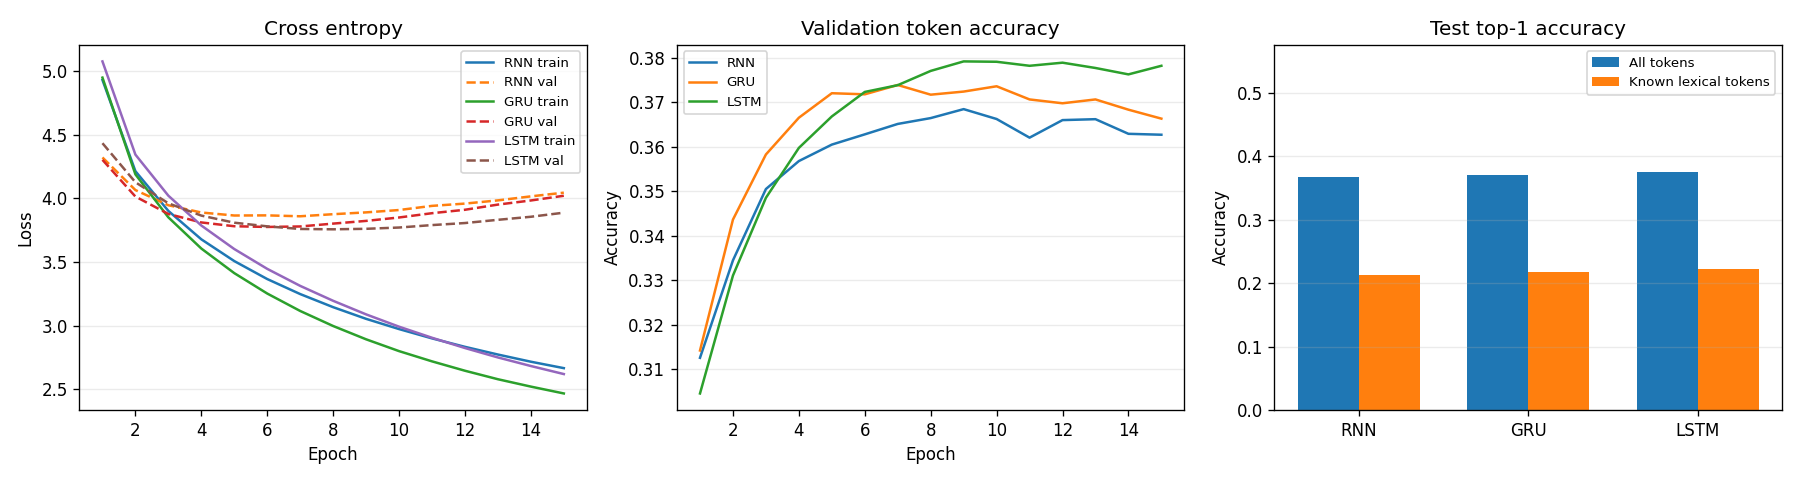

In [12]:
word_figure = plot_word_results(word_results)
plt.show()
show_word_inference(word_results, word_data)

# 可自行替换前缀；sample=True 为温度采样，默认是贪心续写。
# predict_next_words(word_results['LSTM']['model'], '我想', word_data)
# generate_words(word_results['LSTM']['model'], '我想', word_data, sample=True, seed=1)